# Лабораторная работа «Кластеризация»

## Вариант 2

Набор данных: 2liver.csv - сведения о пациентах
и показателях, связанных с заболеваниями печени.

## Цель работы

Изучение алгоритмов и методов кластеризации на практике.

## 1. Загрузка набора данных

Загрузим данные из CSV-файла с помощью библиотеки pandas
и выведем первые пять строк для знакомства со структурой таблицы.

In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "3"

In [2]:
import pandas as pd

df = pd.read_csv("2liver.csv")
df.head()

,Age,Gender,TotalBilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset123
0,65,Female,0.7,0.1,187.0,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699.0,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490.0,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182.0,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195.0,27,59,7.3,2.4,0.40,1


## 2. Предварительная обработка данных

Определим количество строк и столбцов, проверим типы данных,
наличие пропущенных значений и полных дубликатов строк.
По результатам проверки выберем способ обработки данных.

In [3]:
print("Количество строк и столбцов:", df.shape)

print("\nИнформация о столбцах:")
df.info()

print("\nКоличество пропусков по столбцам:")
print(df.isna().sum())

print("\nКоличество полных дубликатов:", df.duplicated().sum())

Количество строк и столбцов: (587, 11)

Информация о столбцах:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 587 entries, 0 to 586
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         587 non-null    int64  
 1   Gender                      587 non-null    object 
 2   TotalBilirubin              585 non-null    float64
 3   Direct_Bilirubin            587 non-null    float64
 4   Alkaline_Phosphotase        586 non-null    float64
 5   Alamine_Aminotransferase    587 non-null    int64  
 6   Aspartate_Aminotransferase  587 non-null    object 
 7   Total_Protiens              587 non-null    float64
 8   Albumin                     587 non-null    float64
 9   Albumin_and_Globulin_Ratio  583 non-null    float64
 10  Dataset123                  587 non-null    object 
dtypes: float64(6), int64(2), object(3)
memory usage: 50.6+ KB

Количество пропусков по сто

Полные дубликаты строк удаляются, чтобы одинаковые записи
не получали дополнительный вес при кластеризации.
Пропуски в числовых признаках заменяются медианами
соответствующих столбцов. Медиана менее чувствительна
к крайним значениям, чем среднее арифметическое.

In [4]:
# Создаём копию исходных данных
df_clean = df.copy()
df_clean.columns = df_clean.columns.str.strip()

# Последний столбец содержит класс пациента
target_column = df_clean.columns[-1]
print("Целевой столбец:", target_column)

# Выбираем признаки без пола и целевого столбца
numeric_features = df_clean.columns.drop(
    ["Gender", target_column]
)

# Преобразуем числовые признаки в числа
for column in numeric_features:
    df_clean[column] = pd.to_numeric(
        df_clean[column], errors="coerce"
    )

print("\nПропуски перед заполнением:")
print(df_clean[numeric_features].isna().sum())

# Удаляем полные дубликаты
duplicates = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().copy()

# Заполняем пропуски медианами
df_clean[numeric_features] = df_clean[numeric_features].fillna(
    df_clean[numeric_features].median()
)

print("\nУдалено дубликатов:", duplicates)
print("Размер таблицы после обработки:", df_clean.shape)

print("\nОставшиеся пропуски:")
print(df_clean.isna().sum())

print("\nЗначения пола:")
print(df_clean["Gender"].value_counts(dropna=False))

print("\nЗначения целевой переменной:")
print(df_clean[target_column].value_counts(dropna=False))

Целевой столбец: Dataset123

Пропуски перед заполнением:
Age                           0
TotalBilirubin                2
Direct_Bilirubin              0
Alkaline_Phosphotase          1
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    1
Total_Protiens                0
Albumin                       0
Albumin_and_Globulin_Ratio    4
dtype: int64

Удалено дубликатов: 15
Размер таблицы после обработки: (572, 11)

Оставшиеся пропуски:
Age                           0
Gender                        0
TotalBilirubin                0
Direct_Bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Protiens                0
Albumin                       0
Albumin_and_Globulin_Ratio    0
Dataset123                    0
dtype: int64

Значения пола:
Gender
Male      430
Female    140
Mal         2
Name: count, dtype: int64

Значения целевой переменной:
Dataset123
1      406
2      165
yes      1
Name: count, dtype: int6

In [5]:
print("Записи с нестандартным значением пола:")
display(df_clean[df_clean["Gender"] == "Mal"])

print("Записи с нестандартным значением целевого класса:")
display(
    df_clean[
        ~df_clean[target_column].astype(str).str.strip().isin(["1", "2"])
    ]
)

Записи с нестандартным значением пола:


,Age,Gender,TotalBilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset123
574,32,Mal,12.1,6.0,515.0,48,92.0,6.6,2.4,0.5,1
586,40,Mal,0.6,0.1,98.0,35,31.0,6.0,3.2,1.1,1


Записи с нестандартным значением целевого класса:


,Age,Gender,TotalBilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset123
89,60,Male,4.0,1.9,238.0,119,350.0,7.1,3.3,0.8,yes


При проверке категориальных значений обнаружены две записи
со значением пола Mal. Оно исправлено на Male как опечатка.

В целевой переменной обнаружено значение yes вместо допустимых
классов 1 и 2. Поскольку достоверно восстановить класс невозможно,
эта запись исключена из дальнейшего исследования.

In [6]:
# Исправляем опечатку в обозначении пола
df_clean["Gender"] = (
    df_clean["Gender"].str.strip().replace({"Mal": "Male"})
)

# Приводим целевой столбец к числовому типу
target_numeric = pd.to_numeric(
    df_clean[target_column], errors="coerce"
)

# Оставляем записи с допустимыми классами
valid_target = target_numeric.isin([1, 2])
print("Исключено записей с некорректным классом:",
      (~valid_target).sum())

df_clean = df_clean.loc[valid_target].copy()
df_clean[target_column] = target_numeric.loc[valid_target].astype(int)

# После исправлений повторно проверяем дубликаты
extra_duplicates = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Дополнительно удалено дубликатов:", extra_duplicates)
print("Итоговый размер таблицы:", df_clean.shape)

print("\nПол:")
print(df_clean["Gender"].value_counts())

print("\nЦелевая переменная:")
print(df_clean[target_column].value_counts())

print("\nВсего пропусков:", df_clean.isna().sum().sum())

Исключено записей с некорректным классом: 1
Дополнительно удалено дубликатов: 2
Итоговый размер таблицы: (569, 11)

Пол:
Gender
Male      429
Female    140
Name: count, dtype: int64

Целевая переменная:
Dataset123
1    405
2    164
Name: count, dtype: int64

Всего пропусков: 0


После предварительной обработки осталось 569 записей.
Пропуски в числовых признаках заполнены медианами,
исправлены опечатки в обозначении пола, удалены полные
дубликаты и одна запись с некорректным целевым классом.

## 3. Выделение целевой переменной

Целевая переменная - последний столбец Dataset123,
содержащий исходные классы пациентов.

Сохраним её отдельно в y и исключим из признаков X.
Кластеризация выполняется без использования известных классов:
они понадобятся для визуализации и оценки результатов.

В основной модели используем только числовые признаки.
Категориальный признак Gender исключим. Его кодирование
рассматривается в дополнительных заданиях методички.

In [7]:
# Исходные классы пациентов
y = df_clean[target_column].copy()

# Числовые признаки для кластеризации
X = df_clean.drop(columns=[target_column, "Gender"]).copy()

print("Размер таблицы признаков X:", X.shape)
print("Размер целевой переменной y:", y.shape)

print("\nПризнаки для кластеризации:")
print(X.columns.tolist())

display(X.head())

Размер таблицы признаков X: (569, 9)
Размер целевой переменной y: (569,)

Признаки для кластеризации:
['Age', 'TotalBilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 'Total_Protiens', 'Albumin', 'Albumin_and_Globulin_Ratio']


,Age,TotalBilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio
0,65,0.7,0.1,187.0,16,18.0,6.8,3.3,0.90
1,62,10.9,5.5,699.0,64,100.0,7.5,3.2,0.74
2,62,7.3,4.1,490.0,60,68.0,7.0,3.3,0.89
3,58,1.0,0.4,182.0,14,20.0,6.8,3.4,1.00
4,72,3.9,2.0,195.0,27,59.0,7.3,2.4,0.40


## 4. Матрица диаграмм рассеяния

Построим матрицу диаграмм рассеяния числовых признаков.
Цветом обозначим исходные классы пациентов.

Вне диагонали показаны взаимосвязи между парами признаков,
а на диагонали - распределения отдельных признаков.
График позволит визуально оценить различия и пересечения классов.

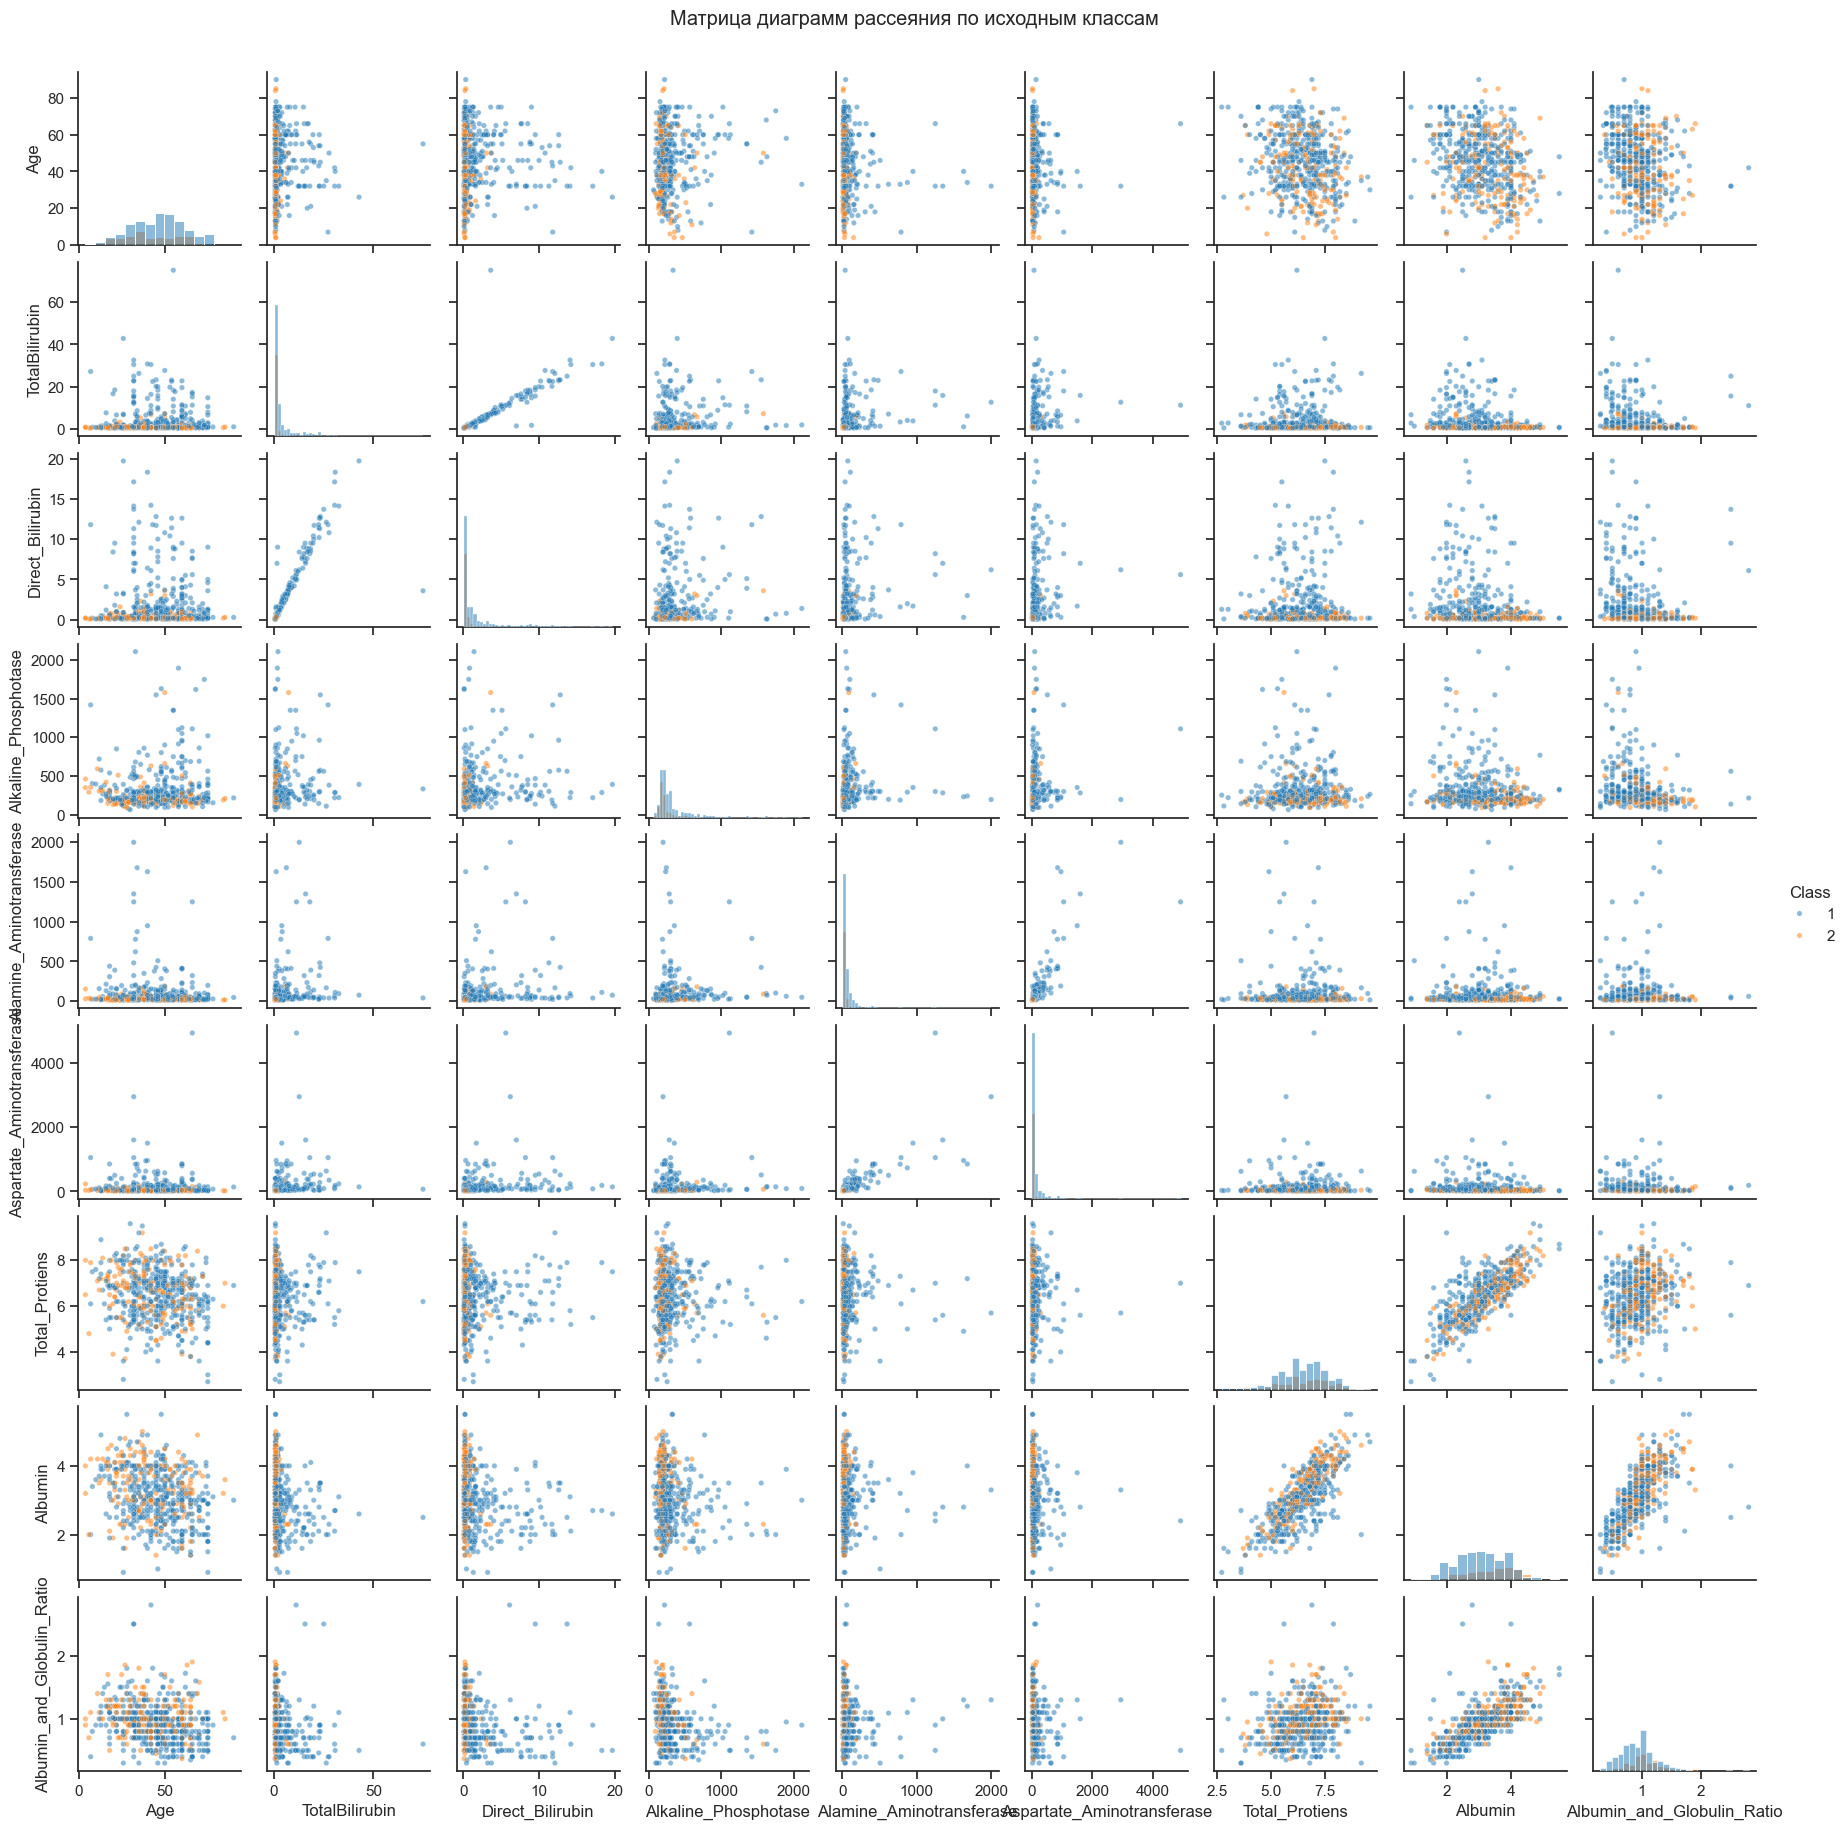

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# Добавляем классы только в таблицу для визуализации
plot_data = X.copy()
plot_data["Class"] = y.astype(str)

sns.set_theme(style="ticks")

g = sns.pairplot(
    data=plot_data,
    vars=X.columns.tolist(),
    hue="Class",
    palette={"1": "tab:blue", "2": "tab:orange"},
    diag_kind="hist",
    height=2,
    plot_kws={"alpha": 0.5, "s": 15}
)

g.fig.suptitle(
    "Матрица диаграмм рассеяния по исходным классам",
    y=1.02
)

plt.show()

По матрице диаграмм рассеяния видно существенное пересечение
исходных классов: чёткого разделения по отдельным парам признаков нет.

Наблюдается положительная связь между общим и прямым билирубином,
а также между общим белком и альбумином. У ряда биохимических
показателей распределения асимметричны и присутствуют крайние значения.
Без дополнительных оснований эти значения не удаляются.

## 5. Стандартизация числовых данных

Признаки имеют разные единицы измерения и диапазоны значений.
Перед кластеризацией выполним стандартизацию с помощью StandardScaler,
чтобы масштаб признаков не определял их вклад в расстояния.

Из каждого значения вычитается среднее соответствующего признака,
затем результат делится на его стандартное отклонение.

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

display(X_scaled.head())

print("Проверка стандартизации:")
display(pd.DataFrame({
    "Среднее": X_scaled.mean(),
    "Стандартное отклонение": X_scaled.std(ddof=0)
}).round(6))

,Age,TotalBilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio
0,1.243243,-0.417288,-0.493028,-0.428277,-0.350808,-0.312932,0.280095,0.189910,-0.151713
1,1.058397,1.209867,1.412957,1.659872,-0.086293,-0.030857,0.923474,0.064406,-0.654146
2,1.058397,0.635577,0.918813,0.807483,-0.108336,-0.140935,0.463918,0.189910,-0.183115
3,0.811936,-0.369431,-0.387140,-0.448669,-0.361829,-0.306052,0.280095,0.315414,0.162309
4,1.674550,0.093192,0.177597,-0.395649,-0.290190,-0.171894,0.739652,-0.939625,-1.721818


Проверка стандартизации:


,Среднее,Стандартное отклонение
Age,-0.0,1.0
TotalBilirubin,0.0,1.0
Direct_Bilirubin,-0.0,1.0
Alkaline_Phosphotase,0.0,1.0
Alamine_Aminotransferase,0.0,1.0
Aspartate_Aminotransferase,-0.0,1.0
Total_Protiens,0.0,1.0
Albumin,-0.0,1.0
Albumin_and_Globulin_Ratio,-0.0,1.0


## 6. Кластеризация методом k-means

Метод k-means разделяет объекты на группы, минимизируя сумму
квадратов расстояний от объектов до центров их кластеров.

Для выбора количества кластеров рассмотрим:
- инерцию - сумму квадратов расстояний до центров кластеров;
- коэффициент силуэта - показатель компактности и разделённости
  кластеров: чем выше его значение, тем лучше.

Проверим количество кластеров от 2 до 10. Выбор выполним
по графику инерции и значениям силуэта, без использования
исходных классов пациентов.

,k,Инерция,Силуэт
0,2,4095.9384,0.4932
1,3,3291.6322,0.2445
2,4,2714.4949,0.2619
3,5,2418.7398,0.2682
4,6,2203.1489,0.2070
5,7,2044.2471,0.2090
6,8,1884.6148,0.2072
7,9,1776.2934,0.2053
8,10,1684.1157,0.2003


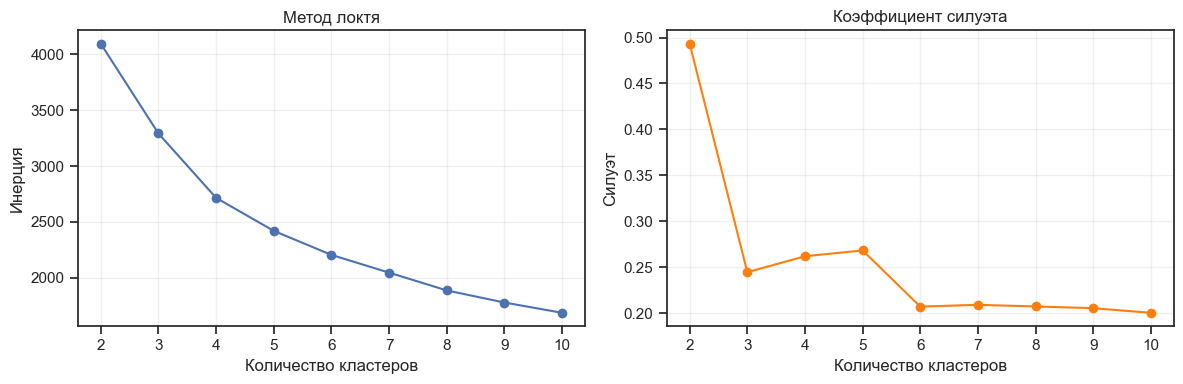

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    results.append({
        "k": k,
        "Инерция": model.inertia_,
        "Силуэт": silhouette_score(X_scaled, labels)
    })

kmeans_results = pd.DataFrame(results)
display(kmeans_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    kmeans_results["k"],
    kmeans_results["Инерция"],
    marker="o"
)
axes[0].set_title("Метод локтя")
axes[0].set_xlabel("Количество кластеров")
axes[0].set_ylabel("Инерция")

axes[1].plot(
    kmeans_results["k"],
    kmeans_results["Силуэт"],
    marker="o",
    color="tab:orange"
)
axes[1].set_title("Коэффициент силуэта")
axes[1].set_xlabel("Количество кластеров")
axes[1].set_ylabel("Силуэт")

for ax in axes:
    ax.set_xticks(range(2, 11))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Наибольший коэффициент силуэта среди проверенных вариантов
получен при k = 2: около 0,4932. При увеличении количества
кластеров силуэт существенно снижается. График инерции
не показывает однозначного резкого перегиба.

Для дальнейшего анализа выбрано два кластера.
Проверим их численность и средние значения признаков.

## 7. Анализ полученных кластеров

Обучим итоговую модель k-means и присвоим каждой записи
номер кластера. С помощью groupby вычислим средние значения
признаков в исходных единицах измерения.
Номера кластеров являются условными обозначениями групп.

In [11]:
# Итоговая модель
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

kmeans_labels = kmeans.fit_predict(X_scaled)

# Признаки в исходных единицах и номера кластеров
kmeans_analysis = X.copy()
kmeans_analysis["Cluster"] = kmeans_labels

print("Количество объектов в каждом кластере:")
display(
    kmeans_analysis.groupby("Cluster")
    .size()
    .rename("Количество")
    .to_frame()
)

print("Средние значения признаков по кластерам:")
kmeans_means = kmeans_analysis.groupby("Cluster").mean()
display(kmeans_means.round(2))

print("Примеры объектов каждого кластера:")
display(
    kmeans_analysis.groupby("Cluster", group_keys=False).head(3)
)

Количество объектов в каждом кластере:


,Количество
Cluster,
0,60
1,509


Средние значения признаков по кластерам:


,Age,TotalBilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio
Cluster,,,,,,,,,
0,45.10,17.45,8.14,450.88,330.65,485.63,6.36,2.66,0.77
1,44.79,1.65,0.71,273.28,50.07,64.57,6.51,3.21,0.97


Примеры объектов каждого кластера:


,Age,TotalBilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Cluster
0,65,0.7,0.1,187.0,16,18.0,6.8,3.3,0.90,1
1,62,10.9,5.5,699.0,64,100.0,7.5,3.2,0.74,0
2,62,7.3,4.1,490.0,60,68.0,7.0,3.3,0.89,1
3,58,1.0,0.4,182.0,14,20.0,6.8,3.4,1.00,1
24,34,4.1,2.0,289.0,875,731.0,5.0,2.7,1.10,0
25,34,6.2,3.0,240.0,1680,850.0,7.2,4.0,1.20,0


Кластер 0 включает 60 пациентов. Для него характерны более
высокие средние значения общего билирубина (17,45),
прямого билирубина (8,14), щелочной фосфатазы (450,88),
АЛТ (330,65) и АСТ (485,63).

Кластер 1 включает 509 пациентов. Средние значения этих
показателей значительно ниже: 1,65; 0,71; 273,28; 50,07
и 64,57 соответственно. Средний уровень альбумина выше:
3,21 против 2,66 в кластере 0.

Средний возраст близок: 45,10 и 44,79 года.
Таким образом, модель преимущественно выделила группу
с более высокими значениями ряда биохимических показателей.
Полученные кластеры нельзя автоматически считать группами
«с заболеванием» и «без заболевания».

## 8. Оценка качества кластеризации k-means

Вычислим внутренние метрики на стандартизированных признаках:
коэффициент силуэта, индекс Калински - Харабаша
и индекс Дэвиса - Болдина.

Для сравнения кластеров с исходными классами используем
скорректированный индекс Рэнда (ARI) и скорректированную
взаимную информацию (AMI). Исходные классы при обучении
модели не использовались.

In [12]:
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    adjusted_mutual_info_score
)

kmeans_metrics = {
    "Силуэт": silhouette_score(X_scaled, kmeans_labels),
    "Калински - Харабаш": calinski_harabasz_score(
        X_scaled, kmeans_labels
    ),
    "Дэвис - Болдин": davies_bouldin_score(
        X_scaled, kmeans_labels
    ),
    "ARI": adjusted_rand_score(y, kmeans_labels),
    "AMI": adjusted_mutual_info_score(y, kmeans_labels)
}

display(
    pd.DataFrame(
        kmeans_metrics,
        index=["K-means"]
    ).T.rename(columns={"K-means": "Значение"}).round(4)
)

,Значение
Силуэт,0.4932
Калински - Харабаш,141.8991
Дэвис - Болдин,1.4525
ARI,-0.0721
AMI,0.0637


Коэффициент силуэта составил 0,4932, индекс Калински - Харабаша -
141,8991, индекс Дэвиса - Болдина - 1,4525. Эти показатели
будут использованы для сравнения с иерархическим методом.

ARI равен -0,0721, AMI - 0,0637. Следовательно, полученные
кластеры слабо согласуются с исходными классами пациентов.
Отрицательный ARI означает согласованность ниже ожидаемой
при случайном распределении с такими размерами групп.

## 9. Иерархическая агломеративная кластеризация

В начале каждый объект представляет отдельный кластер.
Затем кластеры последовательно объединяются.

Используем метод Уорда: на каждом шаге выбирается объединение
с минимальным увеличением внутрикластерной суммы квадратов.
Построим дендрограмму на стандартизированных данных
для выбора количества кластеров.

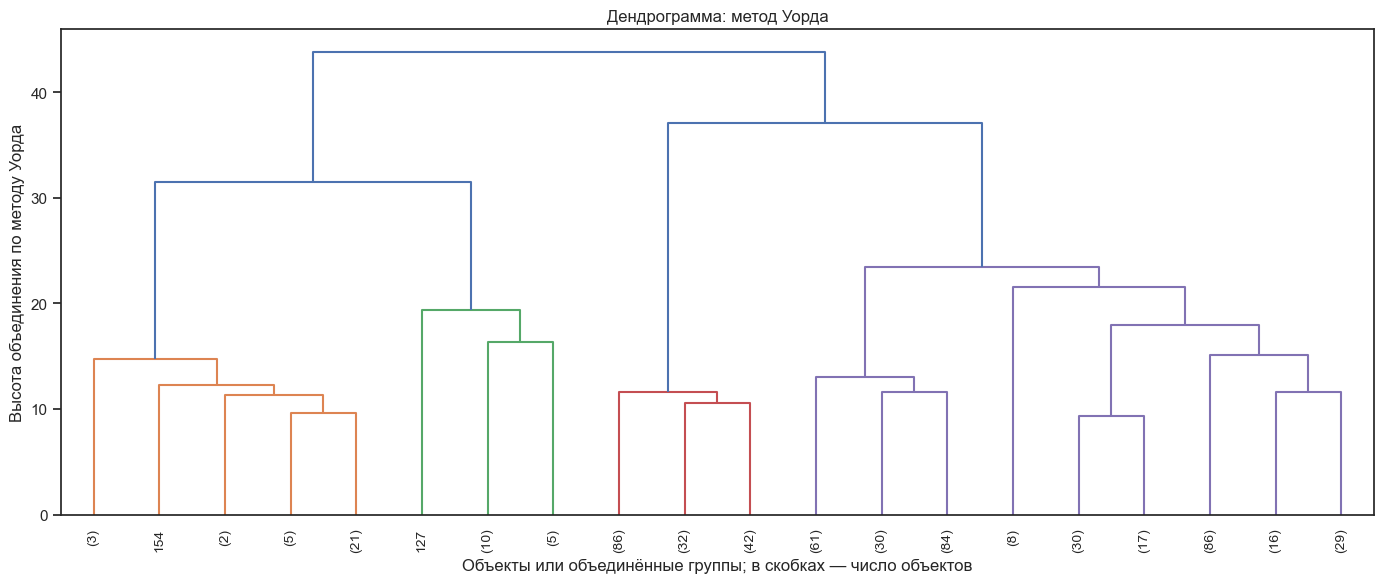

Высоты последних 10 объединений:


,Число кластеров после объединения,Высота объединения
0,10,14.7472
1,9,15.0757
2,8,16.3343
3,7,17.9273
4,6,19.3582
5,5,21.5365
6,4,23.4159
7,3,31.5187
8,2,37.0803
9,1,43.7720


In [13]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Строим иерархию объединений
Z = linkage(X_scaled, method="ward")

# Для читаемости показываем последние 20 групп
plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=20,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Дендрограмма: метод Уорда")
plt.xlabel("Объекты или объединённые группы; в скобках — число объектов")
plt.ylabel("Высота объединения по методу Уорда")
plt.tight_layout()
plt.show()

print("Высоты последних 10 объединений:")
display(pd.DataFrame({
    "Число кластеров после объединения": range(10, 0, -1),
    "Высота объединения": Z[-10:, 2]
}).round(4))

На дендрограмме заметен скачок высоты объединения
с 23,4159 до 31,5187 при переходе от четырёх кластеров
к трём. Это указывает на объединение существенно
различающихся групп.

Поэтому для иерархической кластеризации выбрано
четыре кластера. Вычислим их численность, средние
значения признаков и метрики качества.

In [16]:
from sklearn.cluster import AgglomerativeClustering

# Обучаем модель на стандартизированных данных
agg_model = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward"
)

agg_labels = agg_model.fit_predict(X_scaled)

# Анализируем признаки в исходных единицах
agg_analysis = X.copy()
agg_analysis["Cluster"] = agg_labels

print("Количество объектов в каждом кластере:")
display(
    agg_analysis.groupby("Cluster")
    .size()
    .rename("Количество")
    .to_frame()
)

print("Средние значения признаков по кластерам:")
agg_means = agg_analysis.groupby("Cluster").mean()

# Транспонируем таблицу, чтобы все значения были видны
display(agg_means.T.round(2))

# Вычисляем те же метрики, что для k-means
agg_metrics = {
    "Силуэт": silhouette_score(X_scaled, agg_labels),
    "Калински - Харабаш": calinski_harabasz_score(
        X_scaled, agg_labels
    ),
    "Дэвис - Болдин": davies_bouldin_score(
        X_scaled, agg_labels
    ),
    "ARI": adjusted_rand_score(y, agg_labels),
    "AMI": adjusted_mutual_info_score(y, agg_labels)
}

# Приводим названия метрик к одинаковому виду
def normalize_metric_names(metrics):
    return {
        name.replace("—", "-").replace("–", "-"): value
        for name, value in metrics.items()
    }

kmeans_metrics = normalize_metric_names(kmeans_metrics)
agg_metrics = normalize_metric_names(agg_metrics)

print("Сравнение метрик:")
comparison = pd.DataFrame({
    "K-means (2 кластера)": kmeans_metrics,
    "Иерархический метод (4 кластера)": agg_metrics
})

display(comparison.round(4))

Количество объектов в каждом кластере:


,Количество
Cluster,
0,361
1,16
2,160
3,32


Средние значения признаков по кластерам:


Cluster,0,1,2,3
Age,50.46,41.19,32.74,43.47
TotalBilirubin,2.25,7.14,1.20,24.04
Direct_Bilirubin,1.03,3.33,0.48,10.95
Alkaline_Phosphotase,304.42,307.56,240.68,400.91
Alamine_Aminotransferase,44.89,922.06,60.26,147.69
Aspartate_Aminotransferase,59.81,1301.50,72.42,250.00
Total_Protiens,6.06,5.99,7.47,6.82
Albumin,2.82,2.81,4.02,2.74
Albumin_and_Globulin_Ratio,0.86,0.88,1.17,0.84


Сравнение метрик:


,K-means (2 кластера),Иерархический метод (4 кластера)
Силуэт,0.4932,0.2198
Калински - Харабаш,141.8991,135.4376
Дэвис - Болдин,1.4525,1.2631
ARI,-0.0721,-0.0013
AMI,0.0637,0.0455


### Анализ кластеров иерархического метода

Кластер 0 - 361 пациент. Средний возраст составляет 50,46 года.
По сравнению с кластером 2 наблюдаются более высокие средние
значения билирубина и щелочной фосфатазы, а также более низкие
значения общего белка и альбумина.

Кластер 1 - 16 пациентов. Выделяется самыми высокими средними
значениями АЛТ (922,06) и АСТ (1301,50) среди четырёх групп.

Кластер 2 - 160 пациентов. Характеризуется наименьшим средним
возрастом (32,74 года), самыми низкими средними значениями
общего и прямого билирубина (1,20 и 0,48), а также наиболее
высокими значениями общего белка (7,47) и альбумина (4,02).

Кластер 3 - 32 пациента. Выделяется наиболее высокими средними

значениями общего билирубина (24,04), прямого билирубина
(10,95) и щелочной фосфатазы (400,91).

Иерархический метод позволил выделить группы с различными
профилями биохимических показателей. Номера кластеров условны
и не соответствуют диагнозам или номерам кластеров k-means.

## 10. Выводы по работе

В работе выполнена кластеризация данных о пациентах
с использованием k-means и иерархического агломеративного
метода Уорда.

После предварительной обработки осталось 569 записей.
Были обработаны пропуски и некорректные значения,
удалены дубликаты. Для кластеризации использованы девять
числовых признаков, стандартизированных с помощью StandardScaler.
Целевая переменная в обучение моделей не включалась.

Для k-means выбрано два кластера по максимальному значению
силуэта среди проверенных вариантов от 2 до 10.
Получены группы численностью 60 и 509 пациентов.
Меньшая группа характеризуется более высокими средними
значениями билирубина, щелочной фосфатазы, АЛТ и АСТ.

Для иерархического метода по дендрограмме выбрано четыре
кластера численностью 361, 16, 160 и 32 пациента.
Метод позволил отдельно выделить группы с наиболее высокими
значениями трансаминаз и билирубина.

K-means показал более высокий силуэт: 0,4932 против 0,2198,
и более высокий индекс Калински-Харабаша:
141,8991 против 135,4376.
Иерархический метод показал более низкий, то есть лучший,
индекс Дэвиса-Болдина: 1,2631 против 1,4525.

Однозначного превосходства по всем метрикам нет.
Для укрупнённого разделения данного набора данных
целесообразно использовать k-means с двумя кластерами:
это решение предпочтительнее по двум из трёх внутренних
метрик. Для более подробного изучения структуры данных
полезен иерархический метод с четырьмя кластерами.

Сравнение выполнено для решений с разным количеством
кластеров, поэтому оно характеризует выбранные разбиения,
а не безусловное превосходство одного алгоритма.

ARI и AMI у обоих методов близки к нулю, что указывает
на слабое соответствие кластеров исходным классам.
Следовательно, найденные группы отражают сходство
биохимических показателей и не воспроизводят исходное
разделение пациентов по наличию заболевания.

Цель работы достигнута: изучены и применены два метода
кластеризации, проанализированы группы объектов
и выполнено сравнение качества полученных разбиений.